<a href="https://colab.research.google.com/github/aswathiunnikrishnan/Assignment--1/blob/main/ModuleEndAssessment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy  import stats

In [5]:
df = pd.read_csv('/content/customer_behavior.csv')
print(df.head())

   CustomerID  Gender Region  PurchaseAmount ProductCategory Churn  \
0        1001    Male  South          256.07         Fashion    No   
1        1002  Female  South             NaN     Electronics   Yes   
2        1003  Female   West         1194.41         Fashion    No   
3        1004  Female  South          413.06         Grocery    No   
4        1005    Male   West         1556.32         Fashion   Yes   

  CampaignGroup  
0             A  
1             B  
2             A  
3             A  
4             A  


In [6]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   int64  
 1   Gender           4903 non-null   object 
 2   Region           4825 non-null   object 
 3   PurchaseAmount   4850 non-null   float64
 4   ProductCategory  4474 non-null   object 
 5   Churn            4735 non-null   object 
 6   CampaignGroup    4815 non-null   object 
dtypes: float64(1), int64(1), object(5)
memory usage: 273.6+ KB
None
CustomerID           0
Gender              97
Region             175
PurchaseAmount     150
ProductCategory    526
Churn              265
CampaignGroup      185
dtype: int64


1. find the mean median and mode

In [7]:
x = df["PurchaseAmount"].dropna()
print("mean:",x.mean())
print("median:",x.median())
print("mode:",x.mode().tolist())


mean: 1003.9506701030928
median: 998.0799999999999
mode: [0.0]


2. checking outliers in purchase amount data

In [8]:
q1 = x.quantile(0.25)
q3 = x.quantile(0.75)
iqr = q3-q1
lower_limit = q1-1.5*iqr
upper_limit = q3+1.5*iqr

outliers = x[(x < lower_limit) | (x > upper_limit)]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(outliers))
print(outliers)


Q1: 673.6424999999999
Q3: 1327.0775
IQR: 653.4350000000002
Lower limit: -306.51000000000033
Upper limit: 2307.2300000000005
Number of outliers: 15
195     2318.33
265     2496.41
348     2688.69
411     2349.16
826     2578.89
1358    2384.19
2285    2457.05
2557    2316.19
2681    2400.69
3326    2357.41
3438    2688.88
3564    2643.88
4345    2472.62
4693    2484.75
4808    2642.06
Name: PurchaseAmount, dtype: float64


3. Skewness and kurtosis

In [9]:
print("skewness:",x.skew())
print("kurtosis:",x.kurtosis())



skewness: 0.10609189374631554
kurtosis: -0.2615105545319705


4. Spending betweenmale and female

In [10]:
male = df.loc[df["Gender"]=="Male","PurchaseAmount"].dropna()
female = df.loc[df["Gender"]=="Female","PurchaseAmount"].dropna()

print("Male_mean:",male.mean())
print("Female_mean:",female.mean())

t_stat,p_value = stats.ttest_ind(male,female,equal_var=False)

print("T-statistics:",t_stat)
print("P-value:",p_value)

if p_value<0.05:

  print("significant difference in spending")
else:
  print("no significant difference in spending")

Male_mean: 1019.1766093880973
Female_mean: 987.8720464135021
T-statistics: 2.234798912073049
P-value: 0.025476849797238143
significant difference in spending


5. Relationship between product category and customer churn

In [11]:
contingency_table = pd.crosstab(df["ProductCategory"],df["Churn"])
print(contingency_table)

chi2, p_value, dof, expected = (
    stats.chi2_contingency(contingency_table)
)
print("chi-square statistics:",chi2)
print("P-value:",p_value)
print("Degrees of freedom:",dof)

if p_value<0.05:
  print("significnant association between category and churn")
else:
  print("no significant association")





Churn             No  Yes
ProductCategory          
Electronics      785  541
Fashion          839  607
Grocery          855  604
chi-square statistics: 0.3960436652673918
P-value: 0.8203519424988512
Degrees of freedom: 2
no significant association


6. Purchase Amount variation in regions

In [12]:
regional_groups = [group["PurchaseAmount"].dropna()for region,group in df.groupby("Region")]

#mean purchase amount for each region

print(df.groupby("Region")["PurchaseAmount"].mean())

Region
East     1009.946017
North    1013.017952
South     997.603877
West      995.247327
Name: PurchaseAmount, dtype: float64


In [13]:
f_stat,p_value = stats.f_oneway(*regional_groups)

print("F-statistics:",f_stat)
print("P-value:",p_value)

if p_value<0.05:
  print("siginificant difference between regional means")
else:
  print("no significant difference between regional means")


F-statistics: 0.38966786354806704
P-value: 0.760452802731563
no significant difference between regional means


7. which is better A or B

In [14]:
campaign_a = df.loc[df["CampaignGroup"]=="A","PurchaseAmount"].dropna()
campaign_b = df.loc[df["CampaignGroup"]=="B","PurchaseAmount"].dropna()

print("Campaign A mean:",campaign_a.mean())
print("campaign B mean:",campaign_b.mean())

t_stat,p_value =stats.ttest_ind(campaign_a,campaign_b,equal_var=False)

print("T-statistics:",t_stat)
print("P-value:",p_value)

Campaign A mean: 1011.9455872340425
campaign B mean: 994.3399654874893
T-statistics: 1.2430861943551852
P-value: 0.21389858277292212


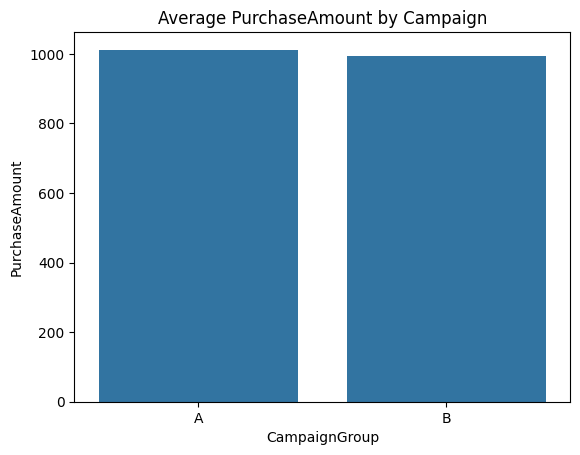

In [15]:
sns.barplot(
    data=df,
    x="CampaignGroup",
    y="PurchaseAmount",
    errorbar=None
)

plt.title("Average PurchaseAmount by Campaign")
plt.show()

since p_value is greater than 0.05 there is no much difference in the average spending of each campaign. so it is difficult to say which one is better

8. Purchase amount distriution

In [16]:
normal_stat,p_value = stats.normaltest(x)
print("Test statistics:",normal_stat)
print("P-value:",p_value)

if p_value<0.05:
  print("Reject normality")
else:
  print("insufficient evidence to reject normality")

Test statistics: 27.251556517359987
P-value: 1.208925924000244e-06
Reject normality


9. Central limit theoram

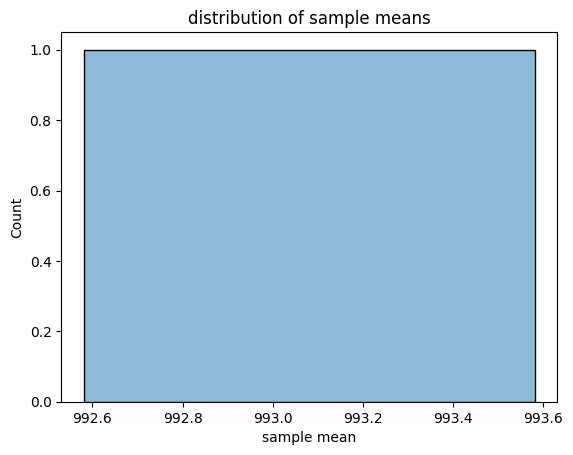

mean of sample means: 993.0809999999999
standard deviation of sample means: nan
Theoretical standard error: 68.18109156358463


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:227: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:219: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


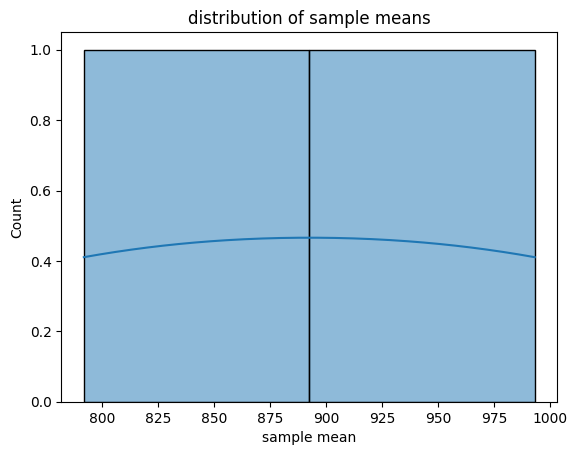

mean of sample means: 892.4914999999999
standard deviation of sample means: 142.25503513232843
Theoretical standard error: 68.18109156358463


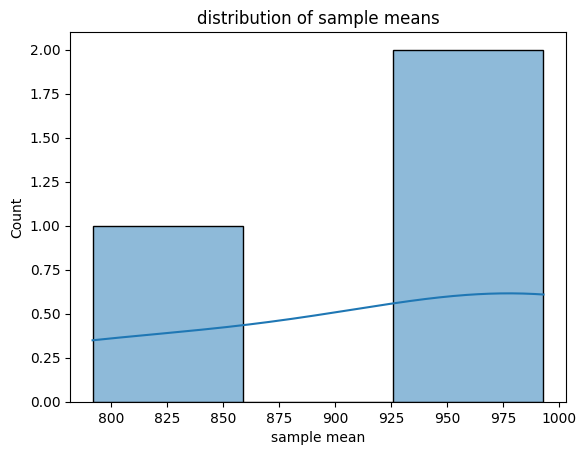

mean of sample means: 923.716
standard deviation of sample means: 114.20663601997921
Theoretical standard error: 68.18109156358463


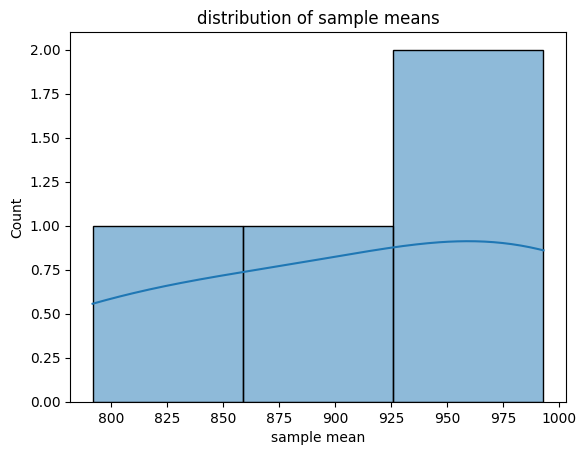

mean of sample means: 913.3787500000001
standard deviation of sample means: 95.51372723811315
Theoretical standard error: 68.18109156358463


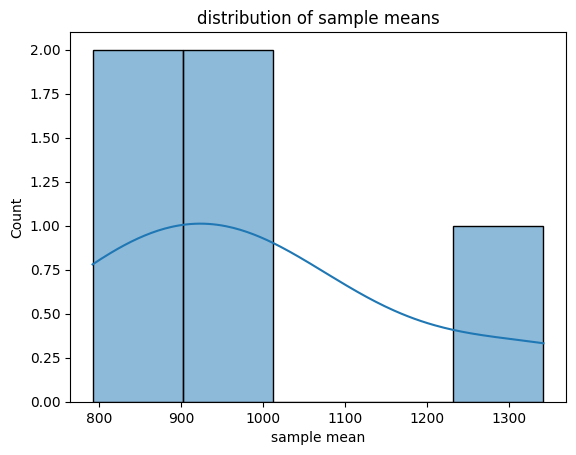

mean of sample means: 999.0922
standard deviation of sample means: 208.7489679560118
Theoretical standard error: 68.18109156358463


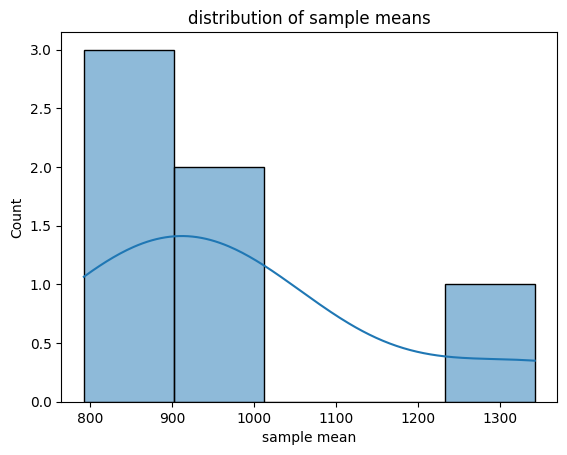

mean of sample means: 980.1258333333334
standard deviation of sample means: 192.4038556925684
Theoretical standard error: 68.18109156358463


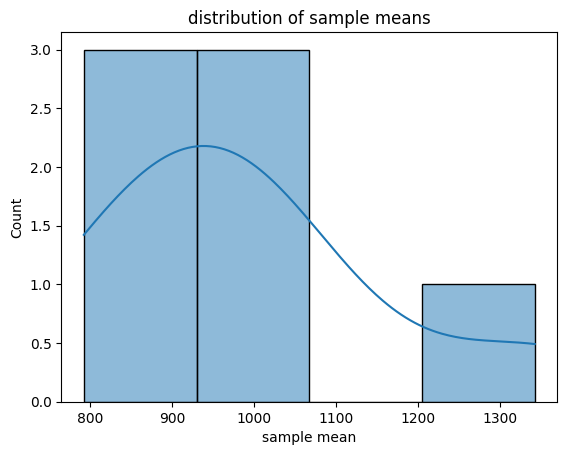

mean of sample means: 989.6185714285714
standard deviation of sample means: 177.42647568392678
Theoretical standard error: 68.18109156358463


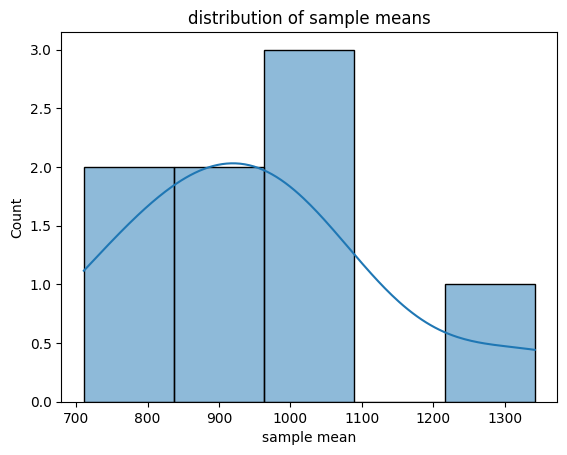

mean of sample means: 954.758
standard deviation of sample means: 191.58565943201495
Theoretical standard error: 68.18109156358463


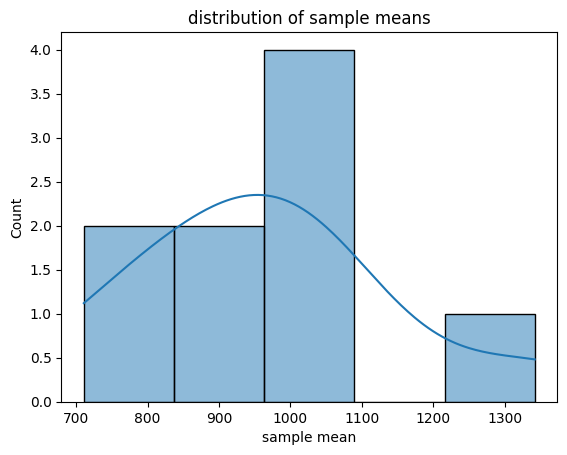

mean of sample means: 966.5057777777778
standard deviation of sample means: 182.64452998090158
Theoretical standard error: 68.18109156358463


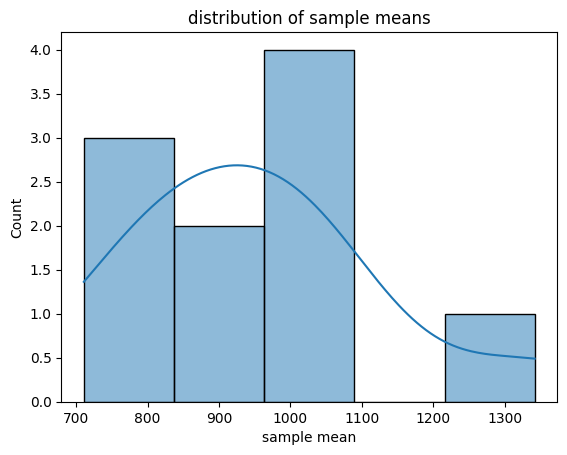

mean of sample means: 953.2491
standard deviation of sample means: 177.2282740701319
Theoretical standard error: 68.18109156358463


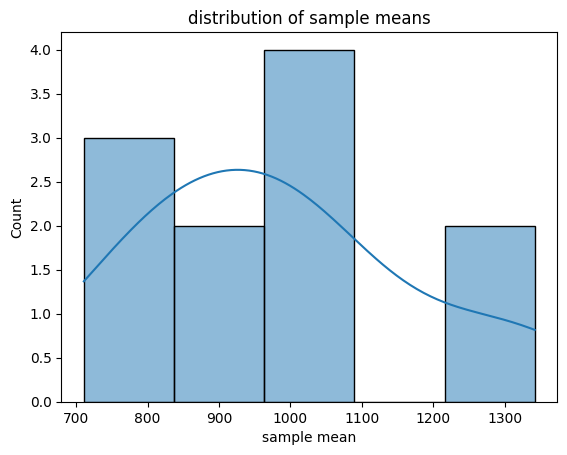

mean of sample means: 981.2529999999999
standard deviation of sample means: 192.08143477233818
Theoretical standard error: 68.18109156358463


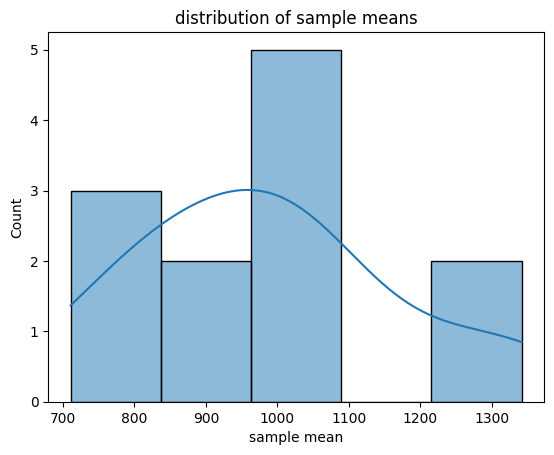

mean of sample means: 985.8875833333333
standard deviation of sample means: 183.84480898917207
Theoretical standard error: 68.18109156358463


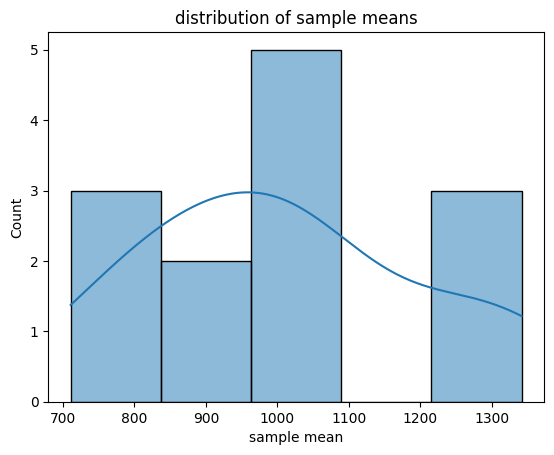

mean of sample means: 1008.6877692307693
standard deviation of sample means: 194.2688030625581
Theoretical standard error: 68.18109156358463


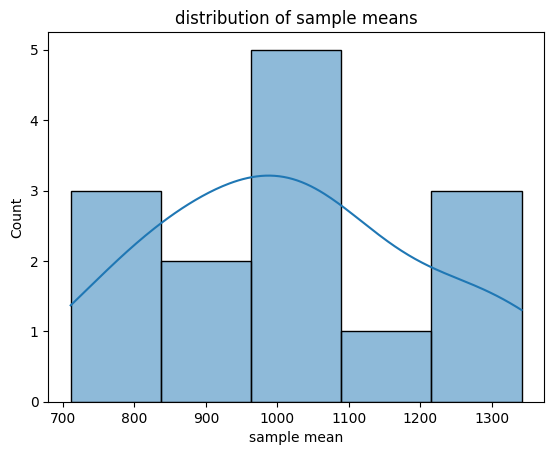

mean of sample means: 1016.5942142857144
standard deviation of sample means: 188.97732364581518
Theoretical standard error: 68.18109156358463


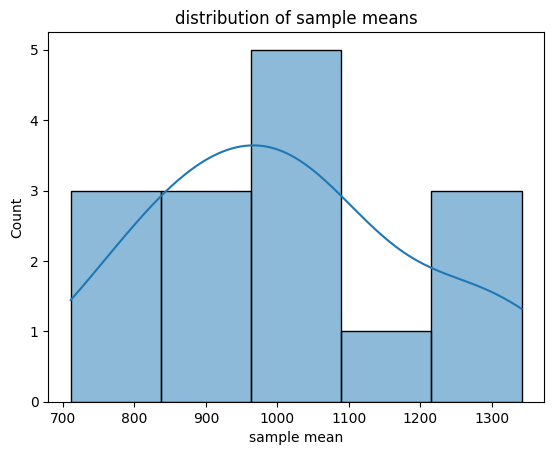

mean of sample means: 1009.6026
standard deviation of sample means: 184.10535334957385
Theoretical standard error: 68.18109156358463


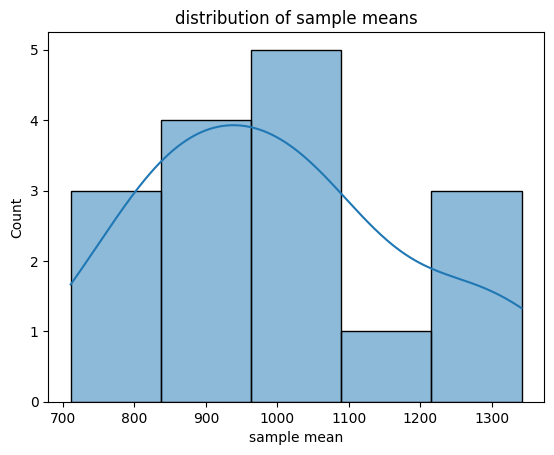

mean of sample means: 998.9056874999999
standard deviation of sample means: 182.93690729054424
Theoretical standard error: 68.18109156358463


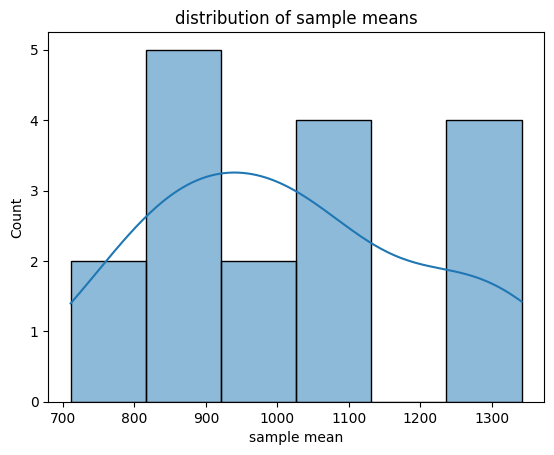

mean of sample means: 1015.2499411764705
standard deviation of sample means: 189.51406603748134
Theoretical standard error: 68.18109156358463


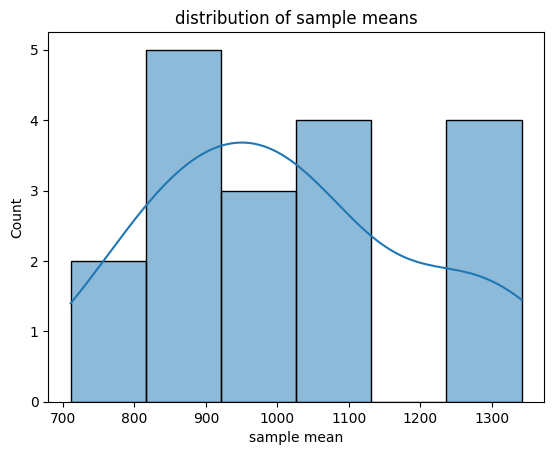

mean of sample means: 1012.9235555555556
standard deviation of sample means: 184.12038789470535
Theoretical standard error: 68.18109156358463


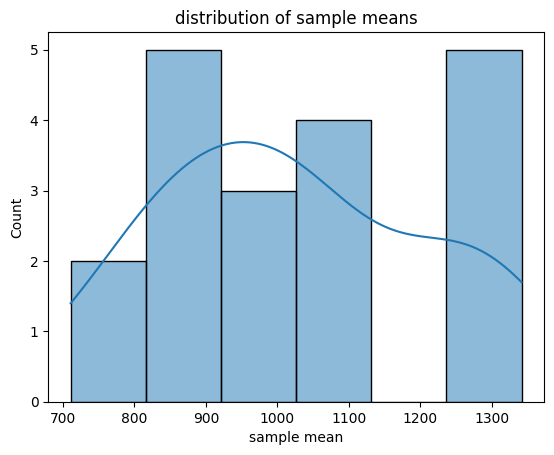

mean of sample means: 1024.899105263158
standard deviation of sample means: 186.39159934393052
Theoretical standard error: 68.18109156358463


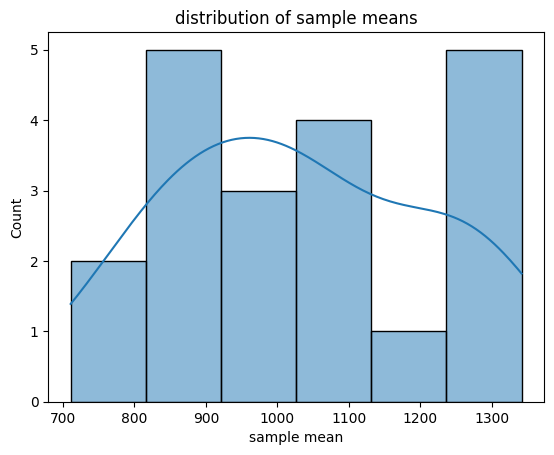

mean of sample means: 1032.5049
standard deviation of sample means: 184.5813460193236
Theoretical standard error: 68.18109156358463


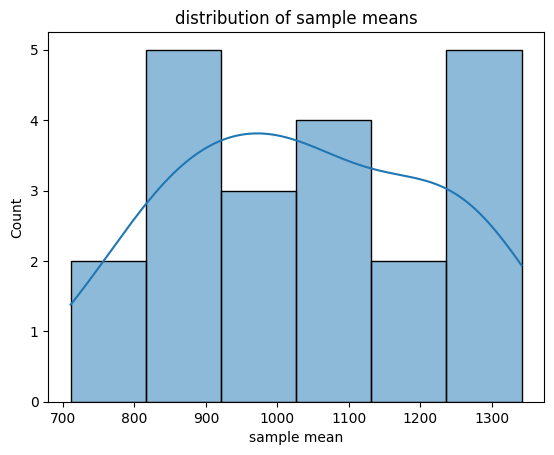

mean of sample means: 1039.401476190476
standard deviation of sample means: 182.66246921456502
Theoretical standard error: 68.18109156358463


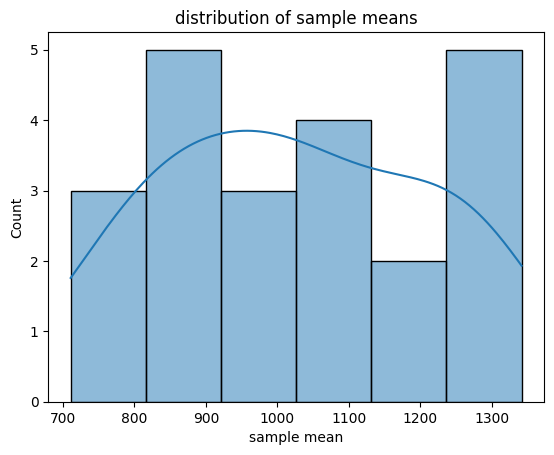

mean of sample means: 1026.6588181818179
standard deviation of sample means: 188.01329196872692
Theoretical standard error: 68.18109156358463


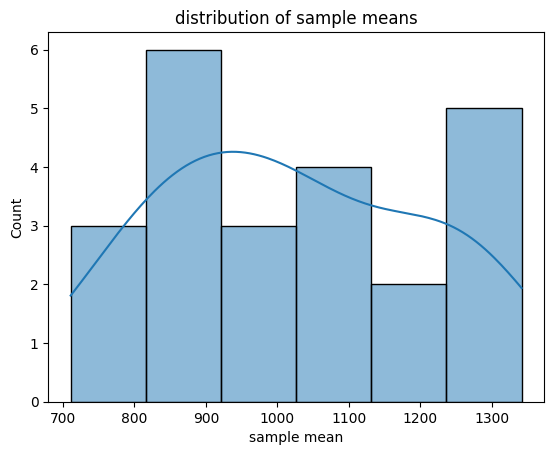

mean of sample means: 1021.5928695652171
standard deviation of sample means: 185.2902953108751
Theoretical standard error: 68.18109156358463


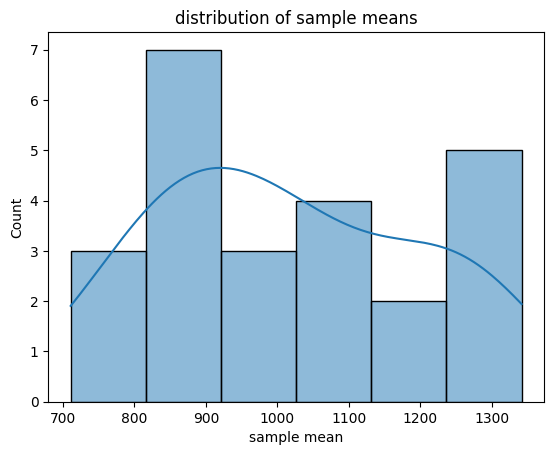

mean of sample means: 1015.5031666666667
standard deviation of sample means: 183.65675587774123
Theoretical standard error: 68.18109156358463


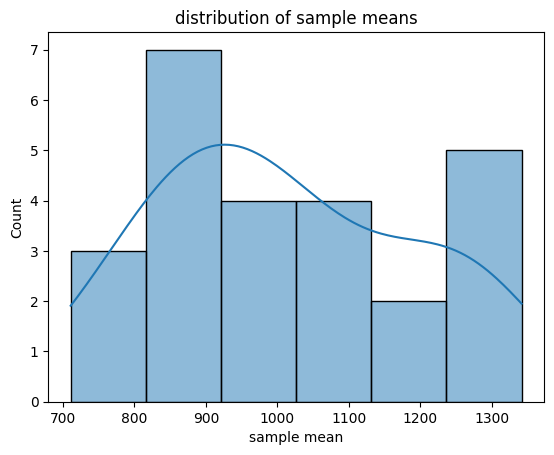

mean of sample means: 1012.8738000000001
standard deviation of sample means: 180.26989406743252
Theoretical standard error: 68.18109156358463


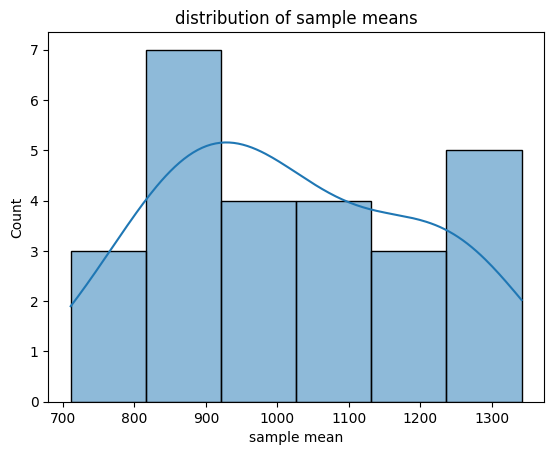

mean of sample means: 1018.5625384615385
standard deviation of sample means: 178.99371691816017
Theoretical standard error: 68.18109156358463


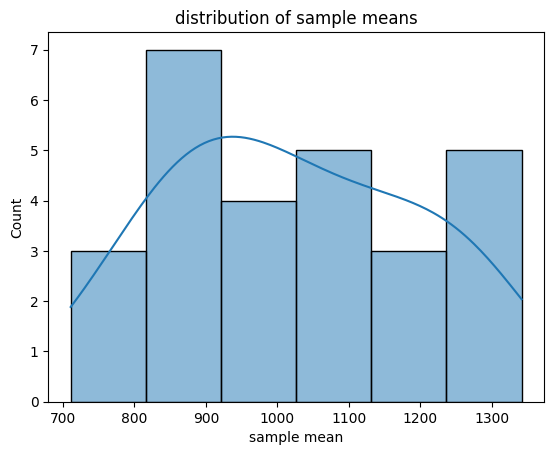

mean of sample means: 1021.7073703703704
standard deviation of sample means: 176.27682826411856
Theoretical standard error: 68.18109156358463


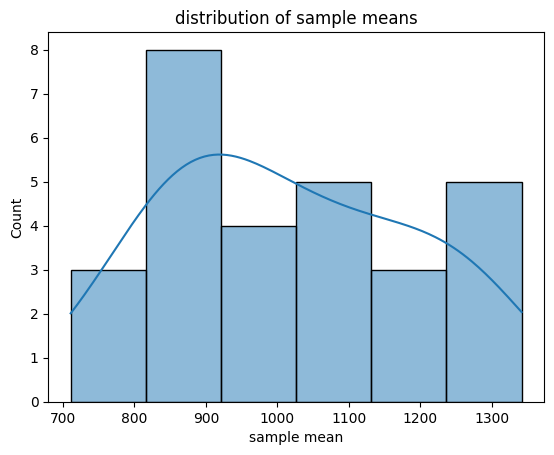

mean of sample means: 1015.736892857143
standard deviation of sample means: 175.84298084820074
Theoretical standard error: 68.18109156358463


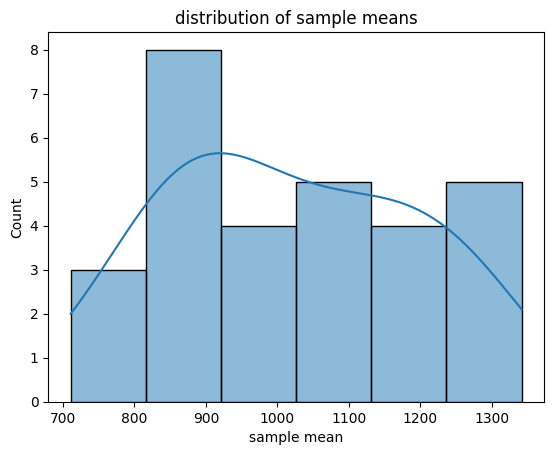

mean of sample means: 1020.8760689655173
standard deviation of sample means: 174.87814064348822
Theoretical standard error: 68.18109156358463


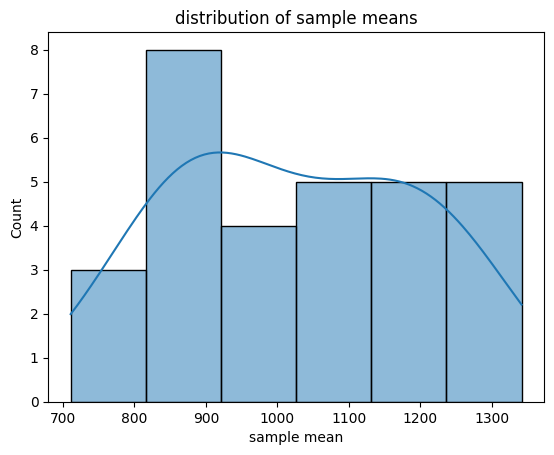

mean of sample means: 1026.4635333333333
standard deviation of sample means: 174.54051832834244
Theoretical standard error: 68.18109156358463


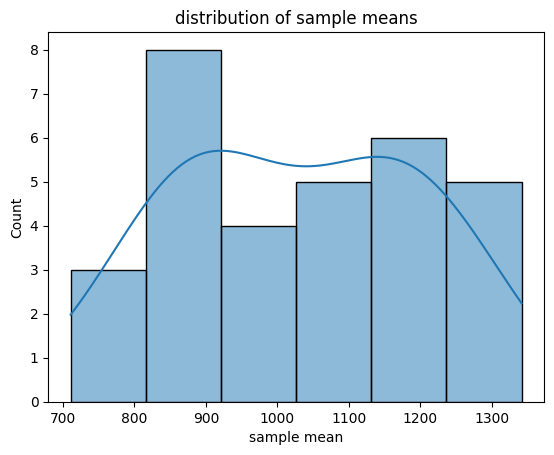

mean of sample means: 1030.2890322580647
standard deviation of sample means: 172.92362617573573
Theoretical standard error: 68.18109156358463


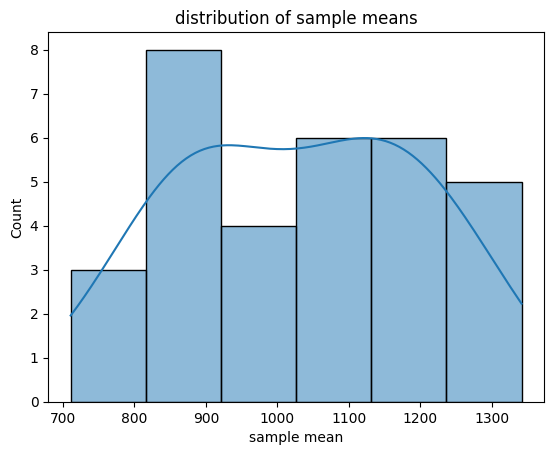

mean of sample means: 1031.79034375
standard deviation of sample means: 170.32353647512772
Theoretical standard error: 68.18109156358463


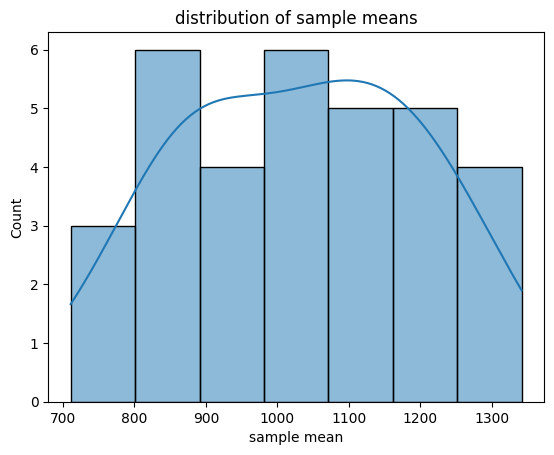

mean of sample means: 1032.2679393939393
standard deviation of sample means: 167.6635573164193
Theoretical standard error: 68.18109156358463


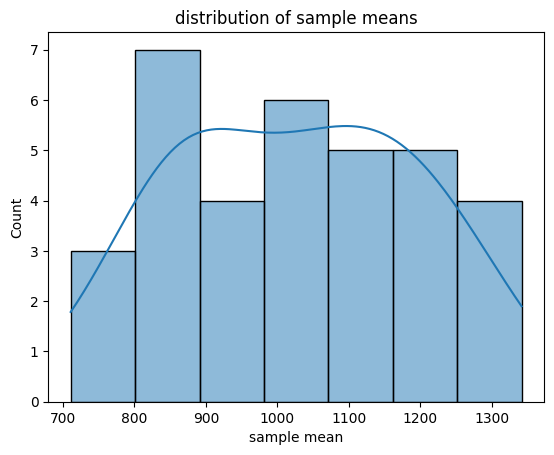

mean of sample means: 1026.6864705882351
standard deviation of sample means: 168.28075614826685
Theoretical standard error: 68.18109156358463


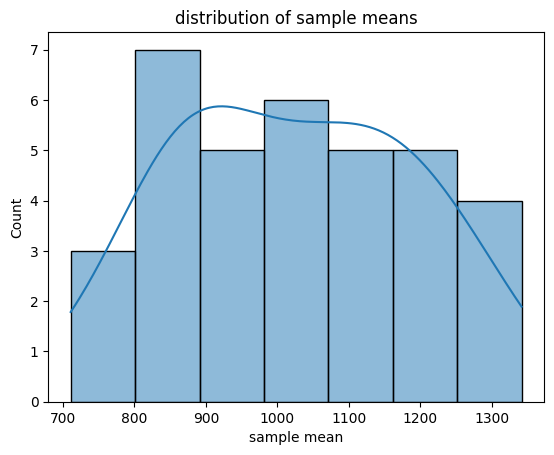

mean of sample means: 1023.8577142857142
standard deviation of sample means: 166.63008002980587
Theoretical standard error: 68.18109156358463


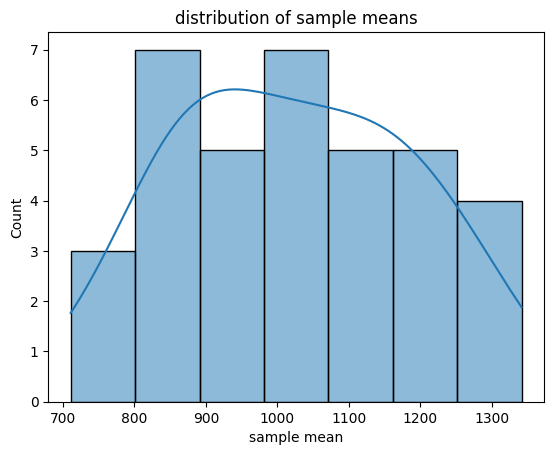

mean of sample means: 1023.1091666666666
standard deviation of sample means: 164.2938003406441
Theoretical standard error: 68.18109156358463


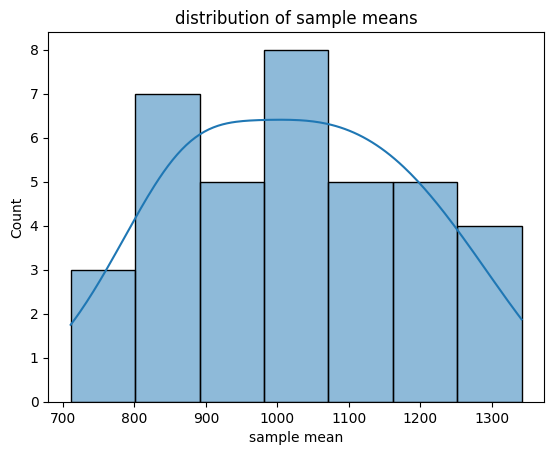

mean of sample means: 1024.2304864864864
standard deviation of sample means: 162.13939905245147
Theoretical standard error: 68.18109156358463


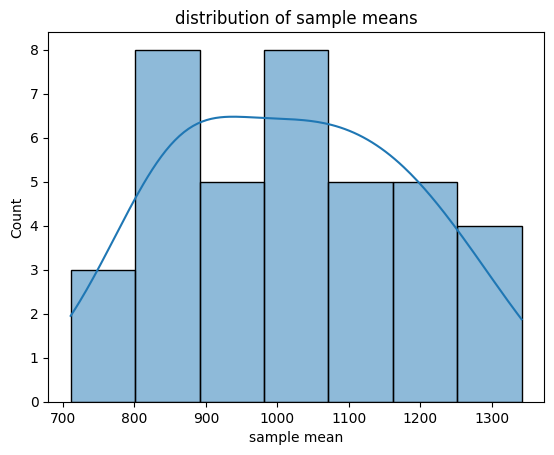

mean of sample means: 1018.6476842105263
standard deviation of sample means: 163.59412613721892
Theoretical standard error: 68.18109156358463


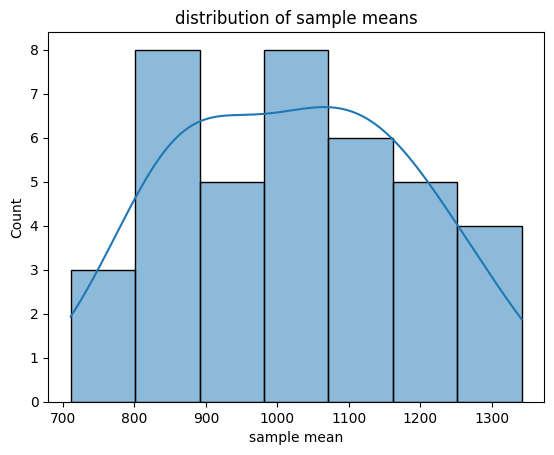

mean of sample means: 1021.2591538461539
standard deviation of sample means: 162.2489408371136
Theoretical standard error: 68.18109156358463


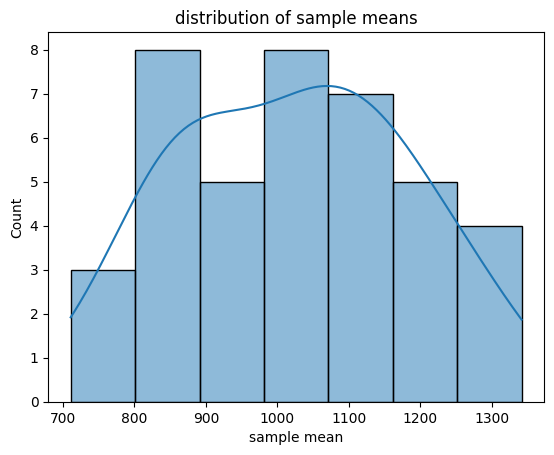

mean of sample means: 1022.54635
standard deviation of sample means: 160.36209330914133
Theoretical standard error: 68.18109156358463


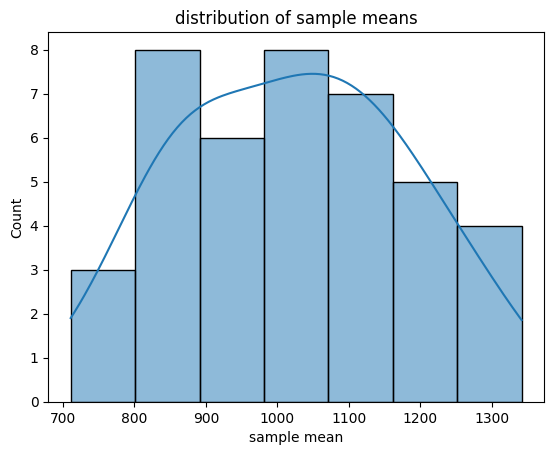

mean of sample means: 1021.4258536585365
standard deviation of sample means: 158.50734033579658
Theoretical standard error: 68.18109156358463


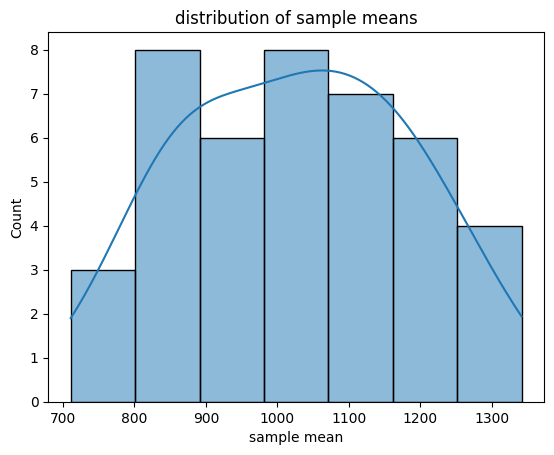

mean of sample means: 1025.6991666666665
standard deviation of sample means: 158.99293365290458
Theoretical standard error: 68.18109156358463


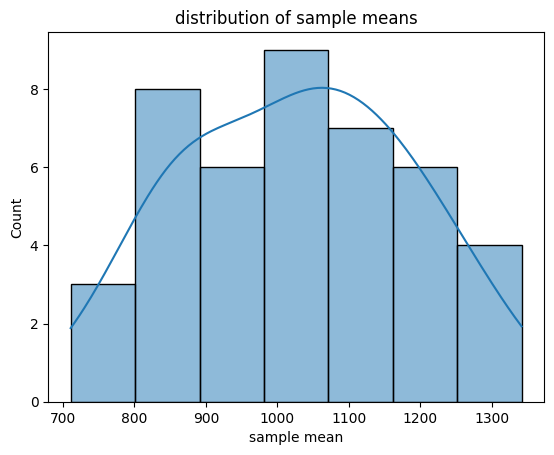

mean of sample means: 1026.5081860465116
standard deviation of sample means: 157.17831247545328
Theoretical standard error: 68.18109156358463


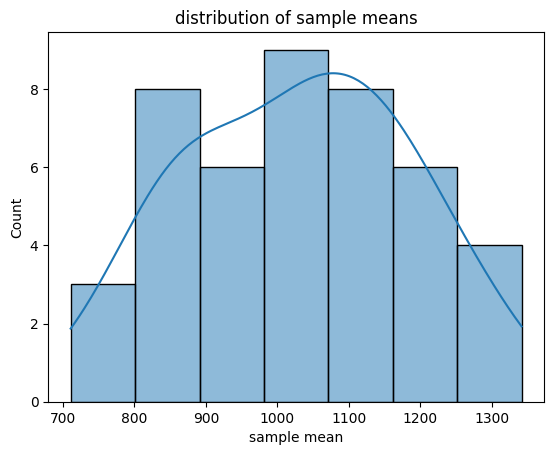

mean of sample means: 1028.8370227272726
standard deviation of sample means: 156.10611663827652
Theoretical standard error: 68.18109156358463


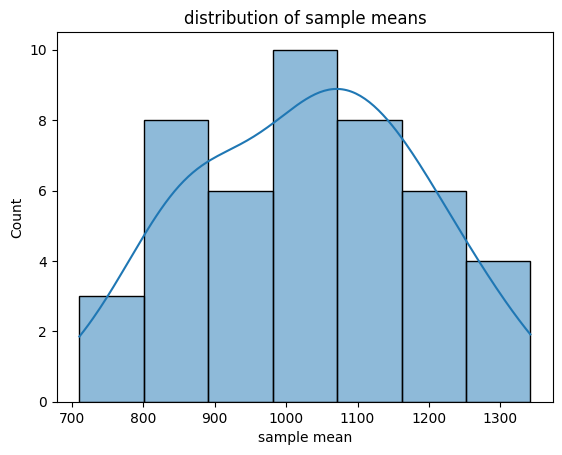

mean of sample means: 1029.2300444444445
standard deviation of sample means: 154.34450750379457
Theoretical standard error: 68.18109156358463


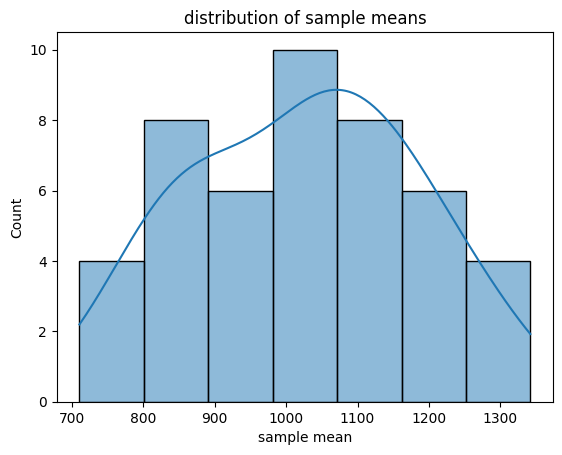

mean of sample means: 1023.7345217391304
standard deviation of sample means: 157.10531367670248
Theoretical standard error: 68.18109156358463


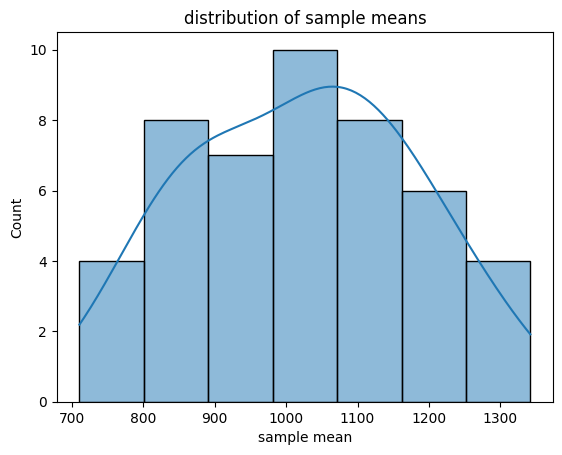

mean of sample means: 1021.6294893617022
standard deviation of sample means: 156.05696786595655
Theoretical standard error: 68.18109156358463


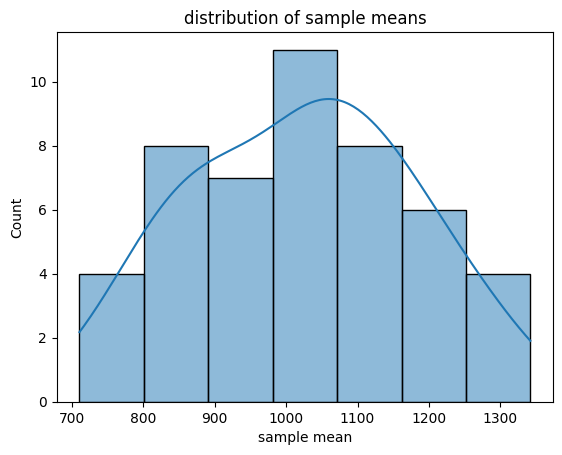

mean of sample means: 1022.051875
standard deviation of sample means: 154.41559315327473
Theoretical standard error: 68.18109156358463


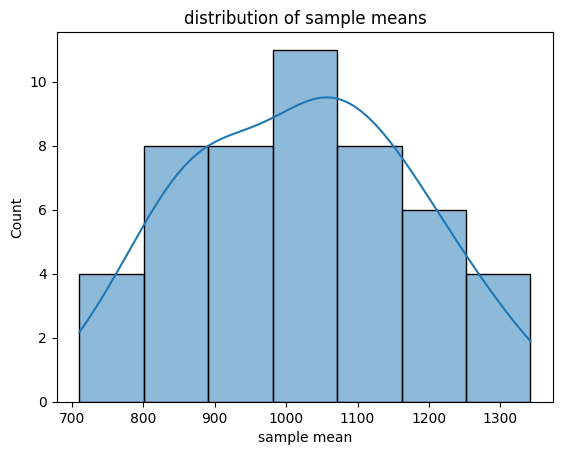

mean of sample means: 1019.474775510204
standard deviation of sample means: 153.85984661945125
Theoretical standard error: 68.18109156358463


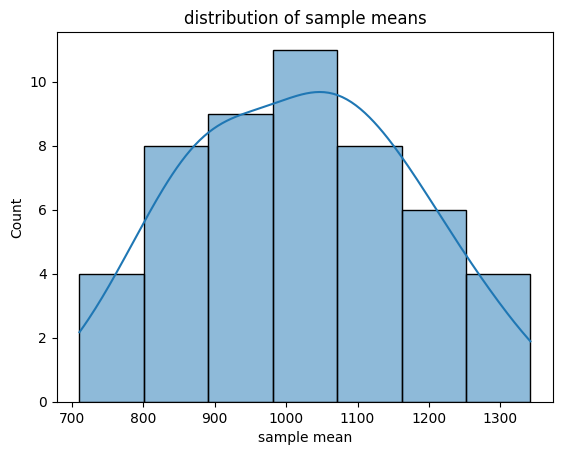

mean of sample means: 1017.9200199999999
standard deviation of sample means: 152.67808028599234
Theoretical standard error: 68.18109156358463


In [ ]:
sample_means = []

for i in range(50):
  sample = x.sample(n=10,replace=True)
  sample_means.append(sample.mean())
  sns.histplot(sample_means,kde=True)

  plt.title("distribution of sample means")
  plt.xlabel("sample mean")
  plt.show()

  print("mean of sample means:",np.mean(sample_means))
  print("standard deviation of sample means:",np.std(sample_means,ddof=1))
  print("Theoretical standard error:",x.std(ddof=1)/np.sqrt(50))


10. 95% confidence interval


In [19]:
n =len(x)
mean = x.mean()
std_error = stats.sem(x)

confidence_interval = stats.t.interval(confidence=0.95,df=n-1,loc=mean,scale=std_error)

print("sample mean:",mean)
print("standard error:",std_error)
print("95% confidence interval:",confidence_interval)

sample mean: 1003.9506701030928
standard error: 6.922740985370976
95% confidence interval: (np.float64(990.3789594609216), np.float64(1017.522380745264))
